# Financial Analysis of Credit Applications

## Purpose
Investigate what the average credit amount hides and compare
financial amounts between applications with and without payment problems.

## Data
The data comes from the Home Credit application training table in Snowflake.
Each row represents one application.

This notebook uses TARGET, AMT_INCOME_TOTAL, AMT_CREDIT and AMT_ANNUITY.

## Approach
Check the loaded data, explore financial distributions and compare
means and medians between TARGET groups.

## Setup

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import snowflake.connector
from dotenv import load_dotenv

In [2]:
load_dotenv("../.env")

True

In [15]:
conn = snowflake.connector.connect(
    account=os.getenv("SNOWFLAKE_ACCOUNT"),
    user=os.getenv("SNOWFLAKE_USER"),
    password=os.getenv("SNOWFLAKE_PASSWORD"),
    warehouse="SNOWFLAKE_LEARNING_WH",
    database="HOME_CREDIT",
    schema="RAW"
)

print("Connected to Snowflake!")

Connected to Snowflake!


## Power BI validation

Compare the four overview cards with calculations from the Snowflake source:
total applications, payment problem count, payment problem rate,
and average credit amount.

The comparison uses the full dataset, with all Power BI filters
and selections cleared.

In [23]:
query = """
SELECT
    COUNT(*) AS TOTAL_APPLICATIONS,
    SUM(CASE WHEN TARGET = 1 THEN 1 ELSE 0 END) AS PAYMENT_PROBLEM_COUNT,
    PAYMENT_PROBLEM_COUNT / TOTAL_APPLICATIONS * 100.0 AS PAYMENT_PERCENTAGE,
    AVG(AMT_CREDIT) AS AVG_CREDIT_AMOUNT
FROM HOME_CREDIT.RAW.APPLICATION_TRAIN;
"""

with conn.cursor() as cursor:
    cursor.execute(query)
    report_validation = pd.DataFrame(
        cursor.fetchall(),
        columns=[column[0] for column in cursor.description]
    )

report_validation

,TOTAL_APPLICATIONS,PAYMENT_PROBLEM_COUNT,PAYMENT_PERCENTAGE,AVG_CREDIT_AMOUNT
0,307511,24825,8.072900,599025.9997057


### Validation result

All four calculated metrics match the unfiltered Power BI overview
cards after rounding to the displayed precision.

## Load Financial Data

In [24]:
#Preview of target variable and some finance variables

query = """
SELECT
    TARGET,
    AMT_INCOME_TOTAL,
    AMT_CREDIT,
    AMT_ANNUITY
FROM APPLICATION_TRAIN
"""
with conn.cursor() as cursor:
    cursor.execute(query)
    applications = pd.DataFrame(
        cursor.fetchall(),
        columns=[column[0] for column in cursor.description]
    )

applications.head()

,TARGET,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY
0,1,202500.000,406597.5,24700.5
1,0,270000.000,1293502.5,35698.5
2,0,67500.000,135000.0,6750.0
3,0,135000.000,312682.5,29686.5
4,0,121500.000,513000.0,21865.5


## Check the Data

In [5]:
applications.shape

(307511, 4)

In [6]:
applications.isna().sum()

TARGET               0
AMT_INCOME_TOTAL     0
AMT_CREDIT           0
AMT_ANNUITY         12
dtype: int64

### Missing Values
AMT_ANNUITY has 12 missing values.
These will remain missing rather than being replaced with zero.

## Financial Distributions

In [7]:
applications.describe()

,TARGET,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY
count,307511.000000,3.075110e+05,3.075110e+05,307499.000000
mean,0.080729,1.687979e+05,5.990260e+05,27108.573909
std,0.272419,2.371231e+05,4.024908e+05,14493.737315
min,0.000000,2.565000e+04,4.500000e+04,1615.500000
25%,0.000000,1.125000e+05,2.700000e+05,16524.000000
50%,0.000000,1.471500e+05,5.135310e+05,24903.000000
75%,0.000000,2.025000e+05,8.086500e+05,34596.000000
max,1.000000,1.170000e+08,4.050000e+06,258025.500000


### Credit Amount
The mean credit amount is approximately 599K, compared with a
median of 513K. This suggests that larger credit amounts pull
the average upward. 

Credit amounts vary substantially, with a standard deviation
of approximately 402K. The mean and median should therefore
be considered together when summarising the data. The maximum credit amount is approximately 4 million.

Together with the mean exceeding the median, this suggests
a distribution extending toward higher credit amounts.
Large values need investigation before being labelled errors.

### Income
The mean of the total income is approximately 169k with a median of 147k so we have some values of income pulling the mean upwards.

The standard deviation is approximately 237,123, indicating
substantial variation. Although 75% of applications have income
at or below 202,500, the maximum is 117 million.

This extreme value needs further investigation. It should not
be treated as an error or removed without checking it.
There are no missing income values.

### Annuity Amount

The mean annuity is approximately 27,109, compared with a median
of 24,903. The higher mean suggests that larger annuity values
pull the average upward.

The standard deviation is approximately 14,494.
The middle 50% of recorded values lie between 16,524 and 34,596,
while the maximum is approximately 258,026.

There are 12 missing annuity values. These remain missing rather
than being replaced with zero. The summary statistics use the
307,499 available values.

In [8]:
applications.nlargest(10, "AMT_INCOME_TOTAL")

,TARGET,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY
12840,1,117000000.0,562491.0,26194.5
226732,0,18000090.0,675000.0,69295.5
259746,0,13500000.0,1400503.5,130945.5
74112,0,9000000.0,1431531.0,132601.5
118878,0,6750000.0,790830.0,52978.5
114613,0,4500000.0,2250000.0,225000.0
173651,0,4500000.0,835380.0,42651.0
195289,0,4500000.0,450000.0,47749.5
217276,0,4500000.0,1755000.0,61132.5
194471,0,3950059.5,675000.0,66217.5


### Investigating Extreme Income Values

The highest recorded income is 117 million, approximately
6.5 times the second highest value of 18 million.

This observation stands apart even among the largest incomes.
Its validity is uncertain, so it remains in the dataset.
A sensitivity check will show how much it affects the summary.

In [9]:
income = applications["AMT_INCOME_TOTAL"]

income_without_max = income.drop(income.idxmax())

pd.DataFrame({
    "All observations": income.agg(["mean", "median", "std"]),
    "Without highest observation": income_without_max.agg(
        ["mean", "median", "std"]
    )
})

,All observations,Without highest observation
mean,168797.919297,168417.992784
median,147150.000000,147150.000000
std,237123.146279,108811.807346


### Sensitivity to the Highest Income

Excluding the highest income observation reduces the standard
deviation by approximately 120,000. This shows that one extreme
value has a substantial effect on the measured spread of incomes.
The mean and the median got just slightly changes, not any signficiant ones.

This is a sensitivity check only. The original dataset remains
unchanged because the observation has not been confirmed as an error.

## Compare Payment Problem Groups

In [10]:
applications.groupby("TARGET")[["AMT_CREDIT", "AMT_ANNUITY", "AMT_INCOME_TOTAL"]].agg(["mean", "median"])

AMT_CREDIT             AMT_ANNUITY          AMT_INCOME_TOTAL  \
                 mean    median          mean   median             mean   
TARGET                                                                    
0       602648.282002  517788.0  27163.623349  24876.0    169077.722266   
1       557778.527674  497520.0  26481.744290  25263.0    165611.760906   

                  
          median  
TARGET            
0       148500.0  
1       135000.0



| Financial amount | Mean TARGET 0 | Mean TARGET 1 | Median TARGET 0 | Median TARGET 1 |
|---|---:|---:|---:|---:|
| Income | 169,078 | 165,612 | 148,500| 135,000 |
| Credit | 602,648 | 557,779 | 517,788 | 497,529 |
| Annuity | 27,164 | 26,482 | 24,876| 25,263 |

### Interpretation

Income and credit amounts have higher means and medians for
TARGET 0. The differences therefore appear in both the averages
and the middle values.

Annuity shows a different pattern: the mean is higher for TARGET 0,
while the median is higher for TARGET 1. Comparing averages alone
would miss this difference.

These are descriptive associations. They do not establish causation
or demonstrate how well these variables predict payment problems.

In [11]:
applications.groupby("TARGET")["AMT_ANNUITY"].quantile(
    [0.25, 0.50, 0.75, 0.95]
).unstack()

,0.25,0.50,0.75,0.95
TARGET,,,,
0,16456.5,24876.0,34749.0,53455.5
1,17361.0,25263.0,32976.0,49866.3


TARGET 1 has slightly higher annuities at the lower quartile
and median. However, TARGET 0 has higher annuities at the
75th and 95th percentiles.

This helps explain why TARGET 0 has a higher mean despite
having a lower median: the comparison changes across
different parts of the distribution.

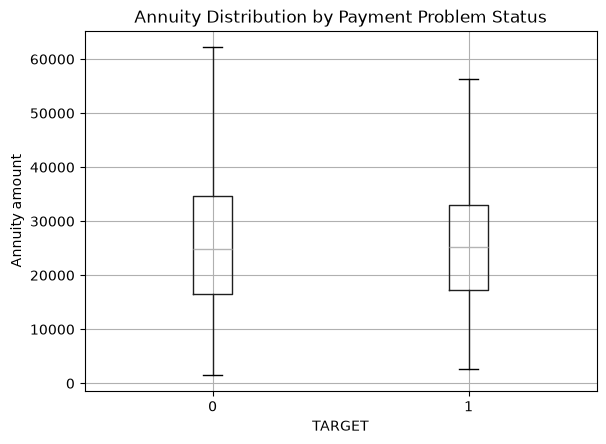

In [12]:
applications.boxplot(column="AMT_ANNUITY", by="TARGET", showfliers=False)
plt.title("Annuity Distribution by Payment Problem Status")
plt.suptitle("")
plt.xlabel("TARGET")
plt.ylabel("Annuity amount")
plt.show()

Points beyond the whiskers are hidden to make the central
distributions easier to compare. All observations remain
included in the box plot calculations.

### Annuity Distribution Comparison

The middle 50% of annuity values overlap substantially between
TARGET groups. TARGET 1 has a slightly higher median, while
TARGET 0 has a wider interquartile range and higher upper percentiles.

These results show why comparing means alone can miss differences
in the distributions. Annuity amounts do not clearly separate
the two groups in this descriptive analysis.

### Main Findings

- Average credit amount is approximately 599K, compared with a
  median of 513K. The average alone does not fully describe
  a typical application.

- Excluding the highest income observation reduces the standard
  deviation by approximately 120K, while the mean changes only
  slightly and the median remains essentially unchanged.
  The original data remains unchanged.

- Income and credit have higher means and medians for TARGET 0.
  Annuity differs: TARGET 1 has a slightly higher median,
  while TARGET 0 has a higher mean and upper percentiles.

### Limitations

- These comparisons describe associations, not causes.
- Group summaries do not establish predictive performance.
- The highest income value has not been confirmed as valid or erroneous.
- Annuity summaries exclude 12 missing values.
- Financial units and currency must be verified before adding
  currency labels.

In [13]:
conn.close()